# Lecture: Relationships Between Categorical Features

A frequency table or bar chart describes the distribution of one categorical feature. Many questions ask whether the distribution of an outcome differs across groups. In this lecture, we will use Titanic passenger records and a simulated A/B test to compare two categorical features.


## Learning goals

By the end of this lecture, you should be able to:

- identify a target feature and a comparison feature;
- create a new categorical feature from a quantitative count;
- create a cross-tabulation of two categorical features;
- distinguish counts, joint percentages, and conditional percentages;
- explain why percentages provide a fairer comparison when groups have different sizes;
- visualize conditional percentages with a bar chart; and
- state a conclusion and limitation supported by the analysis.


## Import the libraries

We use Pandas to read and organize the data and Matplotlib to label and refine the figures.


In [6]:
import pandas as pd 
import matplotlib.pyplot as plt 

titanic_df = pd.read_csv('data/titanic_passengers.csv')

titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Part 1: Survival of Titanic Passengers

RMS *Titanic* sank in the North Atlantic in April 1912. The passenger dataset contains one row for each of 891 passengers. It includes personal and travel information such as passenger name, age, sex, passenger class, family members aboard, port of departure, fare, and survival.

This is a passenger-only dataset. It does not include the ship's crew.


## Data dictionary

| Feature | Description |
| --- | --- |
| `PassengerId` | Unique passenger identifier |
| `Survived` | Survival outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Passenger class: 1 = first, 2 = second, 3 = third |
| `Name` | Passenger name |
| `Sex` | Sex recorded as male or female |
| `Age` | Age in years |
| `SibSp` | Number of siblings or spouses aboard |
| `Parch` | Number of parents or children aboard |
| `Ticket` | Ticket number |
| `Fare` | Passenger fare |
| `Cabin` | Cabin number, when recorded |
| `Embarked` | Port of departure: C = Cherbourg, Q = Queenstown, S = Southampton |

Historical categories and missing values reflect the surviving records and the way this commonly used dataset was prepared.


## Discussion: predict the target feature

1. Which feature should be the target?
2. What does the target feature represent?


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do a few original records support the meaning of the calculation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?


# Research question 1: Who was more likely to survive?


## Step 1 — Question

> **Who was more likely to survive: male or female passengers aboard the Titanic?**

The target feature is `Survived`. The comparison feature is `Sex`.

### Discussion: predict the result

1. Which group do you predict had the higher survival percentage?
2. What historical assumptions or prior knowledge influenced your prediction?


Your prediction:


## Step 2 — Data

Load the local passenger file and inspect the DataFrame. These checks use the same techniques introduced earlier in the course.


In [7]:
titanic_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [8]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
titanic_df.shape

(891, 12)

In [10]:
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Discussion: check the data

1. What does each row represent?
2. Which features are needed for the first research question?
3. Are either of those features missing values?
4. Which other features have missing values?


## Step 3 — Evidence

Begin by examining the distribution of each categorical feature. `.value_counts()` reports the frequency of every category. Adding `normalize=True` divides each frequency by the total, and multiplying by 100 converts the proportions to percentages.


In [11]:
titanic_df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [13]:
titanic_df['Survived'].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [14]:
titanic_df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [15]:
titanic_df['Sex'].value_counts(normalize=True).mul(100).round(2)

Sex
male      64.76
female    35.24
Name: proportion, dtype: float64

### Joint distribution: both features together

A **cross-tabulation**, or cross-tab, displays every combination of two categorical features. The joint distribution describes how observations are distributed across those combinations: female and survived, female and did not survive, male and survived, and male and did not survive.

A count cross-tab shows the joint distribution as frequencies. To express it as **joint percentages**, divide every cell by the total number of passengers: `normalize="all"`. All cells together then add to 100%, rather than each row adding to 100%.


In [16]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


Switch the feature order: the first argument supplies rows and the second supplies columns. Each count stays attached to the same combination; only the table orientation changes. Row-normalized percentages would condition on a different feature after this swap, so the same claim does not apply to conditional percentages.


In [17]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived'], normalize=True).mul(100).round(2)

Survived,0,1
Sex,,
female,9.09,26.15
male,52.53,12.23


A joint percentage answers “What percent of **all passengers** were both female and survivors?” Display the joint percentages and compare their denominator with the count table.


### Conditional distribution: the outcome within a group

A **conditional distribution** describes one feature after restricting attention to a category of the other. Here we condition on sex and examine survival within each sex. “What percent of **female passengers** survived?” uses only female passengers as the denominator.

Counts do not create a fair comparison when the groups contain different numbers of passengers. The question asks for the survival percentage **within each sex**, so each sex must have its own denominator.

`normalize="index"` divides every cell by its row total. Multiplying by 100 makes each row add to 100%. Conditioning on survival instead (using column totals) would answer a different question: the sex distribution within each survival outcome.

| Representation | Denominator | What adds to 100%? |
| --- | --- | --- |
| Joint counts | None; these are numbers of passengers | Not applicable |
| Joint percentages (`normalize="all"`) | All passengers | The entire table |
| Conditional percentages (`normalize="index"`) | Passengers in that row's sex group | Each row |

For example, 233 of 891 passengers were female survivors (26.2% jointly), while 233 of 314 female passengers survived (74.2% conditionally). The numerator is the same; the denominator and question differ.


In [18]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived'], normalize="index").mul(100).round(2)

Survived,0,1
Sex,,
female,25.80,74.20
male,81.11,18.89


### Discussion: counts or percentages?

1. Are the male and female groups the same size?
2. Why would comparing only the number of survivors be unfair?
3. In the percentage table, what population is used as the denominator for each row?


### Compare count and conditional-percentage bar charts

First plot the joint counts. Each full bar shows the number of passengers in that sex group, and its sections show the numbers who did and did not survive. Keep the category order and colors the same in both charts so the change in scale is easy to see.


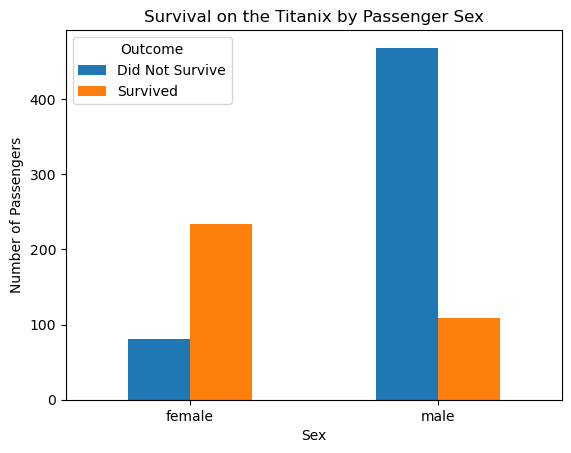

In [20]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived']).plot(kind="bar")

plt.title('Survival on the Titanix by Passenger Sex') 
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.legend(['Did Not Survive', 'Survived'], title='Outcome')
plt.show()

Now plot the conditional percentages. Each complete bar reaches 100%. Use `plt.legend(labels=[...])` to relabel outcomes in plotted column order (0, then 1), without renaming the table columns. `thistle` represents nonsurvivors and `darkseagreen` represents survivors.

If a legend covers the bars, move it outside: `loc="upper left"` selects the legend corner and `bbox_to_anchor=(1.02, 1)` places that corner just beyond the right edge of the axes. `plt.tight_layout()` leaves room for labels and the legend.


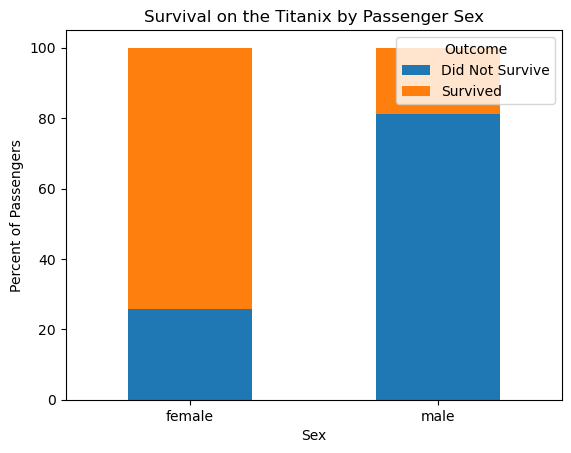

In [27]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived'], normalize='index').mul(100).plot(kind="bar", stacked=True)
plt.title('Survival on the Titanix by Passenger Sex') 
plt.ylabel('Percent of Passengers')
plt.xticks(rotation=0)
plt.legend(['Did Not Survive', 'Survived'], title='Outcome')
plt.show()

### A simpler view: show only the percentage who survived

Select column `1` to show survival alone. With two complete outcome categories, the nonsurvival percentage is 100 minus the survival percentage. This chart communicates the same conditional distribution with fewer marks; it does not show the group sizes.


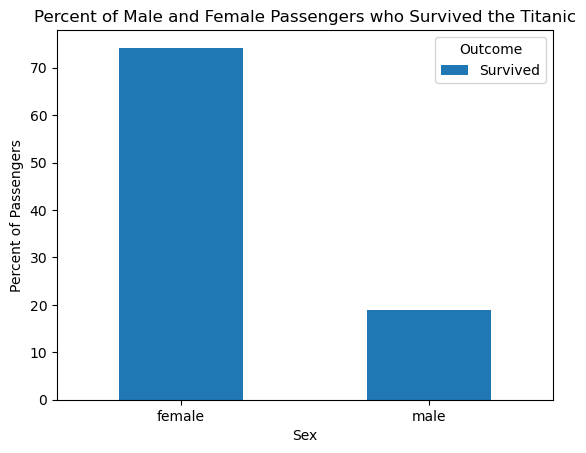

In [31]:
pd.crosstab(titanic_df['Sex'],titanic_df['Survived'], normalize='index').mul(100)[1].plot(kind="bar")
plt.title('Percent of Male and Female Passengers who Survived the Titanic') 
plt.ylabel('Percent of Passengers')
plt.xticks(rotation=0)
plt.legend(['Survived'], title='Outcome')
plt.show()

### Discussion: interpret the evidence

1. Why is the male bar taller in the count chart, while both bars reach 100% in the conditional-percentage chart?
2. What does the green section measure in each chart? Which chart directly answers our question about survival likelihood within each sex?
3. Approximately what percentage of each group survived? Does this support your prediction?
4. Which is easier to interpret: the stacked conditional-percentage chart or the survivor-only chart? How can you recover the percentage who did not survive?
5. If we plotted joint percentages instead, would both full bars reach 100%? Explain using the denominator.


## Step 4 — Check

**Does the survival percentage use all passengers of that sex as its denominator, or only survivors? Looking at the count table, does the larger or smaller share of survivors in each group agree with the table and figure? What survival percentages would make you suspicious because they would not make sense?**


## Step 5 — Conclusion

In this passenger dataset, female passengers were more likely to survive than male passengers. The difference is large: roughly three-quarters of female passengers survived, compared with fewer than one-fifth of male passengers.


## Step 6 — Limitation

This is an observational historical dataset, not a randomized experiment. Sex was related to survival, but it was also related to decisions about evacuation and may have been related to age, passenger class, cabin location, and access to lifeboats. The comparison does not establish that sex alone caused the difference.


# Research question 2: Traveling with parents or children


## Step 1 — Question

> **Were passengers traveling with parents or children more likely to survive than passengers traveling without parents or children?**

`Parch` is a count, but the question asks about two groups. We will create a categorical comparison feature before calculating survival percentages.

### Discussion: predict the result

1. Which group do you predict had the higher survival percentage?
2. Why might traveling with parents or children be related to survival?


Your prediction:


## Step 2 — Data

Use `Parch` and `Survived`. We already inspected missing values. Look at the frequency of each number of parents or children aboard.


In [32]:
titanic_df['Parch'].value_counts()

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

Some `Parch` categories have very few observations, so their percentages can change greatly with just one passenger. Collapsing categories makes the comparison easier to interpret, but can hide differences. Two reasonable choices are:

- **Two groups:** no parents/children versus any parents/children.
- **Three groups:** none, one, or two or more.

Begin with two groups, then compare with three. Choose groups for their meaning and support in the data, not to produce a preferred result.


## Step 3 — Evidence

Create `with_parents_children`: 0 means no parent or child recorded aboard; 1 means at least one. The Boolean comparison converts to integers using `.astype(int)`. Keep the original `Parch` counts.


In [34]:
titanic_df.loc[titanic_df['Parch'] > 0, 'with_parents_children'] = 1
titanic_df.loc[titanic_df['Parch'] == 0, 'with_parents_children'] = 0

pd.crosstab(titanic_df['Parch'], titanic_df['with_parents_children'])


with_parents_children,0.0,1.0
Parch,,
0,678,0
1,0,118
2,0,80
3,0,5
4,0,4
5,0,5
6,0,1


Check the coding across every original category using a cross-tab, rather than previewing a few rows. Do all zero counts map to 0 and all positive counts map to 1?


In [36]:
pd.crosstab(titanic_df['with_parents_children'], titanic_df['Survived'])

Survived,0,1
with_parents_children,,
0.0,445,233
1.0,104,109


### Joint distribution: counts


**Is this conclusion correct?**

> Because 233 people traveling without parents and children survived, compared with 109 traveling with parents and children, people traveling without parents and children were more likely to survive.

What information is missing from that reasoning?


### Conditional distribution: percentages within each group

Use the number of passengers in each travel group as its denominator. Display and plot only the percentage who survived (column `1`).


In [37]:
pd.crosstab(titanic_df['with_parents_children'], titanic_df['Survived'], normalize='index').mul(100).round(2)

Survived,0,1
with_parents_children,,
0.0,65.63,34.37
1.0,48.83,51.17


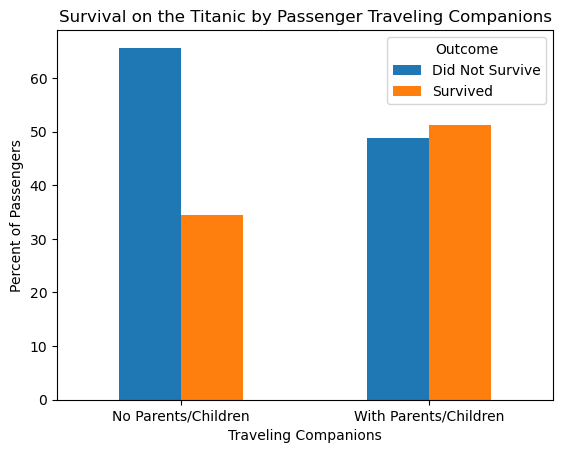

In [43]:
pd.crosstab(titanic_df['with_parents_children'], titanic_df['Survived'], normalize='index').mul(100).round(2).plot(kind="bar")
plt.title('Survival on the Titanic by Passenger Traveling Companions')
plt.ylabel("Percent of Passengers")
plt.xlabel('Traveling Companions')
plt.xticks([0,1],['No Parents/Children','With Parents/Children'], rotation=0)
plt.legend(['Did Not Survive', 'Survived'], title='Outcome')
plt.show()

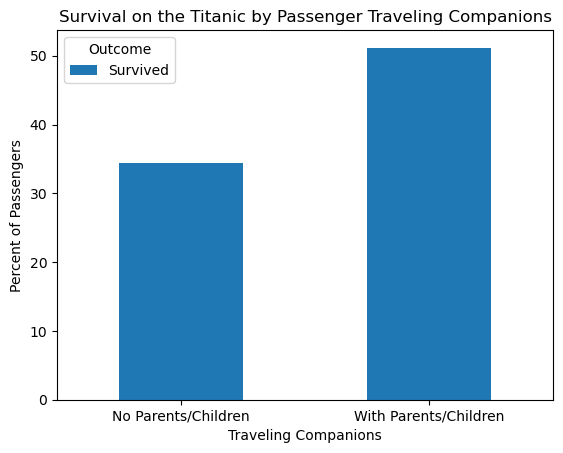

In [45]:
pd.crosstab(titanic_df['with_parents_children'], titanic_df['Survived'], normalize='index').mul(100)[1].round(2).plot(kind="bar")
plt.title('Survival on the Titanic by Passenger Traveling Companions')
plt.ylabel("Percent of Passengers")
plt.xlabel('Traveling Companions')
plt.xticks([0,1],['No Parents/Children','With Parents/Children'], rotation=0)
plt.legend(['Survived'], title='Outcome')
plt.show()

**Which chart is easier to interpret for our research question: raw numbers or conditional percentages? Which group has the higher survival percentage, and how does that compare with your prediction?**

If a legend overlaps the data, how could you move it? Explain the `loc` and `bbox_to_anchor` arguments used above.


### Repeat with three groups: none, one, or two or more

Does combining everyone with any parents/children hide a difference between one and two or more? Record a prediction before calculating.


Your prediction:


Here 0 means none, 1 means one, and 2 means two or more. Reuse the same calculations and charts.


In [47]:

titanic_df.loc[titanic_df['Parch'] > 0, 'with_parents_children_3_cat'] = 1
titanic_df.loc[titanic_df['Parch'] == 0, 'with_parents_children_3_cat'] = 0
titanic_df.loc[titanic_df['Parch'] > 1, 'with_parents_children_3_cat'] = 2

pd.crosstab(titanic_df['Parch'], titanic_df['with_parents_children_3_cat'])


with_parents_children_3_cat,0.0,1.0,2.0
Parch,,,
0,678,0,0
1,0,118,0
2,0,0,80
3,0,0,5
4,0,0,4
5,0,0,5
6,0,0,1


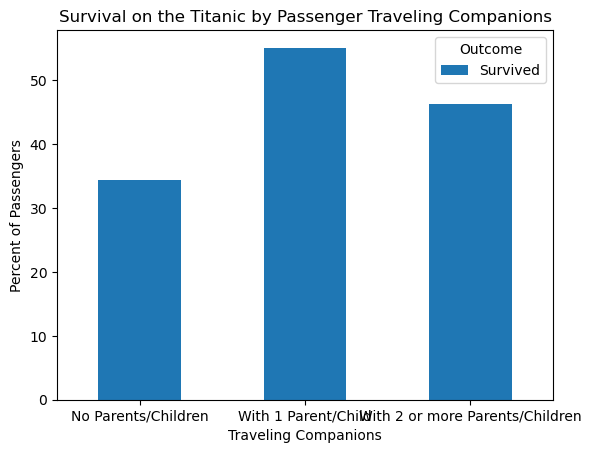

In [49]:
pd.crosstab(titanic_df['with_parents_children_3_cat'], titanic_df['Survived'], normalize='index').mul(100)[1].round(2).plot(kind="bar")
plt.title('Survival on the Titanic by Passenger Traveling Companions')
plt.ylabel("Percent of Passengers")
plt.xlabel('Traveling Companions')
plt.xticks([0,1,2],['No Parents/Children','With 1 Parent/Child', 'With 2 or more Parents/Children'], rotation=0)
plt.legend(['Survived'], title='Outcome')
plt.show()

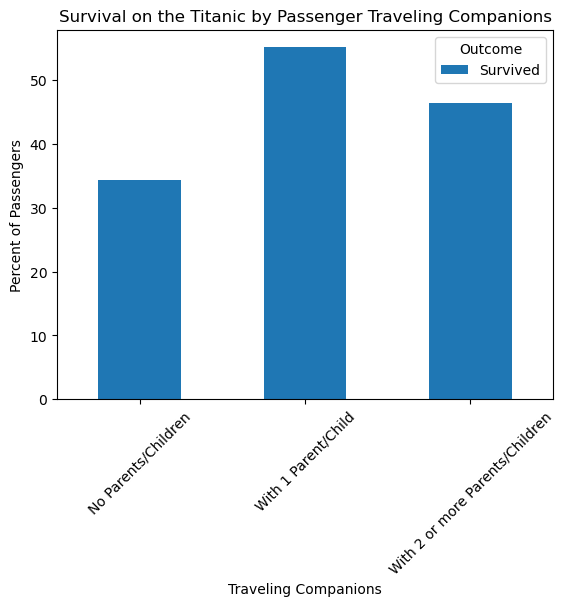

In [50]:
pd.crosstab(titanic_df['with_parents_children_3_cat'], titanic_df['Survived'], normalize='index').mul(100)[1].round(2).plot(kind="bar")
plt.title('Survival on the Titanic by Passenger Traveling Companions')
plt.ylabel("Percent of Passengers")
plt.xlabel('Traveling Companions')
plt.xticks([0,1,2],['No Parents/Children','With 1 Parent/Child', 'With 2 or more Parents/Children'], rotation=45)
plt.legend(['Survived'], title='Outcome')
plt.show()

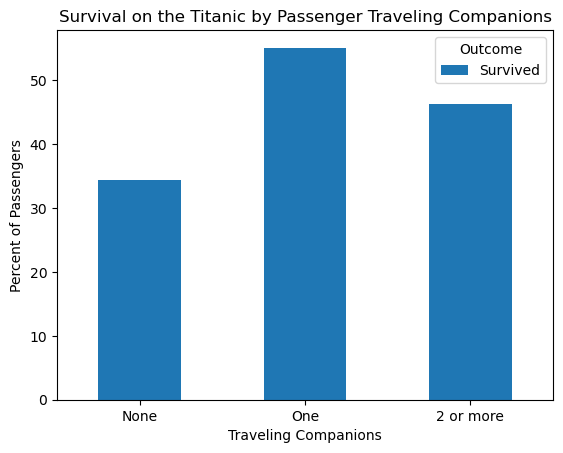

In [51]:
pd.crosstab(titanic_df['with_parents_children_3_cat'], titanic_df['Survived'], normalize='index').mul(100)[1].round(2).plot(kind="bar")
plt.title('Survival on the Titanic by Passenger Traveling Companions')
plt.ylabel("Percent of Passengers")
plt.xlabel('Traveling Companions')
plt.xticks([0,1,2],['None','One', '2 or more'], rotation=0)
plt.legend(['Survived'], title='Outcome')
plt.show()

**What additional information does the three-group comparison reveal? Does it suggest that survival always increases as the number of parents/children increases? What detail is still hidden within “two or more”?**


## Step 4 — Check

Review the coding cross-tabs: does each original `Parch` value appear only in its intended group? Do the conditional percentages use all passengers in each group as the denominator? A zero does not establish that a passenger traveled alone: siblings, spouses, or other companions may still have been aboard.

### Checking code is not the same as verifying historical records

Our cross-tabs can confirm how we coded this file, but cannot establish that every historical entry is accurate. Titanic datasets have been reconstructed and revised; we cannot be absolutely certain of every recorded value. Compare these documented versions:

- [Titanic dataset history and titanic3](https://hbiostat.org/data/repo/titanic): the maintainers describe removing duplicate passengers, correcting errors, and filling missing ages.
- [titanic5 update and comparison with titanic3](https://hbiostat.org/data/repo/titanic5): the compiler reports differences especially in age, with 51 missing ages rather than 263 among 1,309 passengers, and documents how ages were derived.

These are documented disagreements and revisions, not proof that a particular `Parch` entry in our file is wrong. Different row totals can also reflect different coverage, such as including crew or using a training subset. Before comparing values, match the same people and feature definitions.

**If two sources disagree, what documentation would you consult? How should uncertainty about the historical records affect the strength of our conclusion?**


## Step 5 — Conclusion

In this dataset, passengers recorded with any parents/children had a higher survival percentage than those with none (51.2% versus 34.4%). Splitting the former group reveals 55.1% for one and 46.3% for two or more. These results describe recorded groups, not an effect caused by traveling with family.


## Step 6 — Limitation

`Parch` records only the number of parents or children aboard. The dataset documentation notes that some children who traveled with a nanny have `Parch` equal to 0. The feature also does not describe every family relationship, who stayed together during the evacuation, or whether a passenger was traveling with other companions. The groups may differ in age, class, and other features related to survival. This relationship should not be interpreted as proof that traveling with parents or children caused survival.


# Part 2: A/B Testing

An **A/B test** randomly assigns participants to one of two versions of a product, message, or experience. The outcome is then compared across the two experimental conditions.

Random assignment is what makes an A/B test different from the Titanic comparisons. When the groups are created randomly and the experiment is conducted well, a difference in the response can provide evidence that the tested version affected the outcome.


## Example: a museum membership page

A science museum wants more website visitors to begin a free membership. It randomly assigns visitors to one of two pages:

- `Standard page`: the existing page with several membership choices;
- `Simplified page`: a shorter page with one prominent free-membership button.

The response feature `Signed_up` records whether each visitor completed the free-membership signup.

This is a **simulated teaching dataset**. The observations were created to make the structure and interpretation of an A/B test easy to see; they are not evidence about a real museum or website.


## Step 1 — Question

> **Did visitors shown the simplified page sign up more often than visitors shown the standard page?**

### Discussion: identify the features and predict

1. Which feature is the experimental condition?
2. Which feature is the response?
3. Which page do you predict will have the higher signup percentage?


Your prediction:


## Step 2 — Data


In [52]:
museum_df = pd.read_csv('data/museum_signup_ab.csv')
museum_df.head()

,Visitor_id,Page_version,Signed_up
0,M001,Standard page,Yes
1,M002,Standard page,Yes
2,M003,Standard page,Yes
3,M004,Standard page,Yes
4,M005,Standard page,Yes


In [53]:
museum_df['Page_version'].value_counts()

Page_version
Standard page      60
Simplified page    60
Name: count, dtype: int64

In [54]:
museum_df['Signed_up'].value_counts()

Signed_up
No     63
Yes    57
Name: count, dtype: int64

## Step 3 — Evidence

Inspect the condition and response frequencies, then calculate counts and signup percentages within each page version.


In [56]:
pd.crosstab(museum_df['Page_version'], museum_df['Signed_up'])

Signed_up,No,Yes
Page_version,,
Simplified page,21,39
Standard page,42,18


Text(0.5, 1.0, 'A/B Test of Museum Membership Pages')

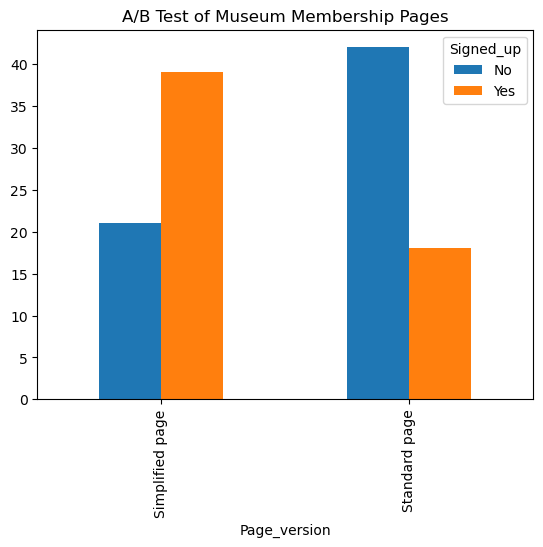

In [58]:
pd.crosstab(museum_df['Page_version'], museum_df['Signed_up']).plot(kind='bar')

plt.title('A/B Test of Museum Membership Pages')

Text(0.5, 1.0, 'A/B Test of Museum Membership Pages')

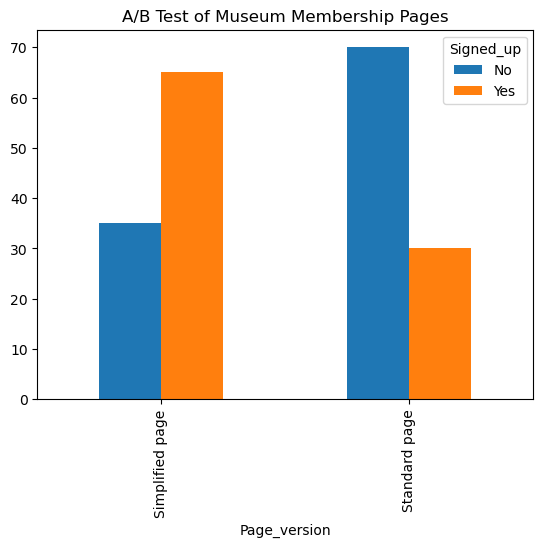

In [59]:
pd.crosstab(museum_df['Page_version'], museum_df['Signed_up'], normalize='index').mul(100).plot(kind='bar')

plt.title('A/B Test of Museum Membership Pages')

### Compare signup frequencies and conditional percentages

Plot both signup outcomes in the count chart to show group sizes. Display and plot only the conditional percentage who signed up (`Yes`), using all visitors assigned to each page as the denominator.


### Discussion: interpret the A/B test

1. What percentage of visitors signed up after seeing each page?
2. What is the difference in percentage points?
3. Which figure is easier to interpret? Here both page groups contain 60 visitors; how would unequal group sizes affect the count comparison?
4. Does the result support your prediction?


## Step 4 — Check

**Does the count table show a majority signing up for the simplified page and a minority for the standard page, as the percentages and figure suggest? Are we calculating the percentage who signed up within each page version, or the percentage of signups who saw each page? What would make you suspicious?**


## Step 5 — Conclusion

In this simulated experiment, visitors assigned to the simplified page signed up substantially more often than visitors assigned to the standard page.


## Step 6 — Limitation

Because this dataset was simulated for teaching, the result cannot support a real product decision. In a real A/B test, we would also verify that random assignment and data collection worked as intended and use statistical inference to assess uncertainty before deciding whether to change the website.


## Procedure for comparing categorical features

1. Identify the target or response feature and the comparison feature.
2. Inspect the frequency of each feature.
3. Create a count cross-tab.
4. Identify the denominator implied by the research question.
5. Calculate the joint or conditional percentages required by the question.
6. Choose a figure that makes the comparison clear.
7. Check whether the values, group meanings, and denominators make sense in context.
8. State a conclusion and limitation.


## Key takeaways

- The target or response feature is the outcome we want to understand.
- A cross-tab describes the joint distribution of two categorical features.
- Counts describe how many observations appear in each combination of categories.
- Conditional percentages describe the response within each comparison group.
- `normalize="index"` makes every row add to 100%.
- A calculated categorical feature can turn a quantitative count into groups that match a research question.
- Random assignment distinguishes an experiment from an observational comparison.
- An observed relationship should be reported with a limitation and should not automatically be interpreted as causal.


# Closing demonstration: Titanic passenger dendrograms

A **dendrogram** displays how hierarchical clustering combines observations into larger groups. This demonstration brings together the Titanic features before we leave this dataset. The code is provided so we can focus on reading the figure and comparing the groups.

We use six passenger features to build a hierarchy using Ward's method, then examine two, three, and five clusters.

1. Begin with each passenger as a separate cluster.
2. Merge clusters successively; Ward's method chooses the merge with the smallest increase in within-cluster squared variation.
3. Read each merge at its vertical height in the tree. Lower merges join more similar groups under this method.
4. Cut the tree into a chosen number of clusters and inspect their characteristics.

The horizontal order is a layout of the tree, not a scale of passenger similarity. A cluster is an exploratory grouping, not a known passenger category.


In [66]:
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from matplotlib.lines import Line2D

titanic_cluster_df = titanic_df.copy()
titanic_cluster_df["Sex"] = titanic_cluster_df["Sex"].map({"male": 0, "female": 1})
titanic_cluster_df["Age"] = titanic_cluster_df["Age"].fillna(titanic_cluster_df["Age"].median())
cluster_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(titanic_cluster_df[cluster_features])
linkage_matrix = sch.linkage(cluster_scaled, method="ward")


## Read the tree

Survival is not used to form the clusters; it is shown afterward to help interpret them. The full tree retains all 891 passengers. Leaf-label colors indicate survival: `green` for survived and `red` for did not survive. The gray branches encode the hierarchy, not survival.


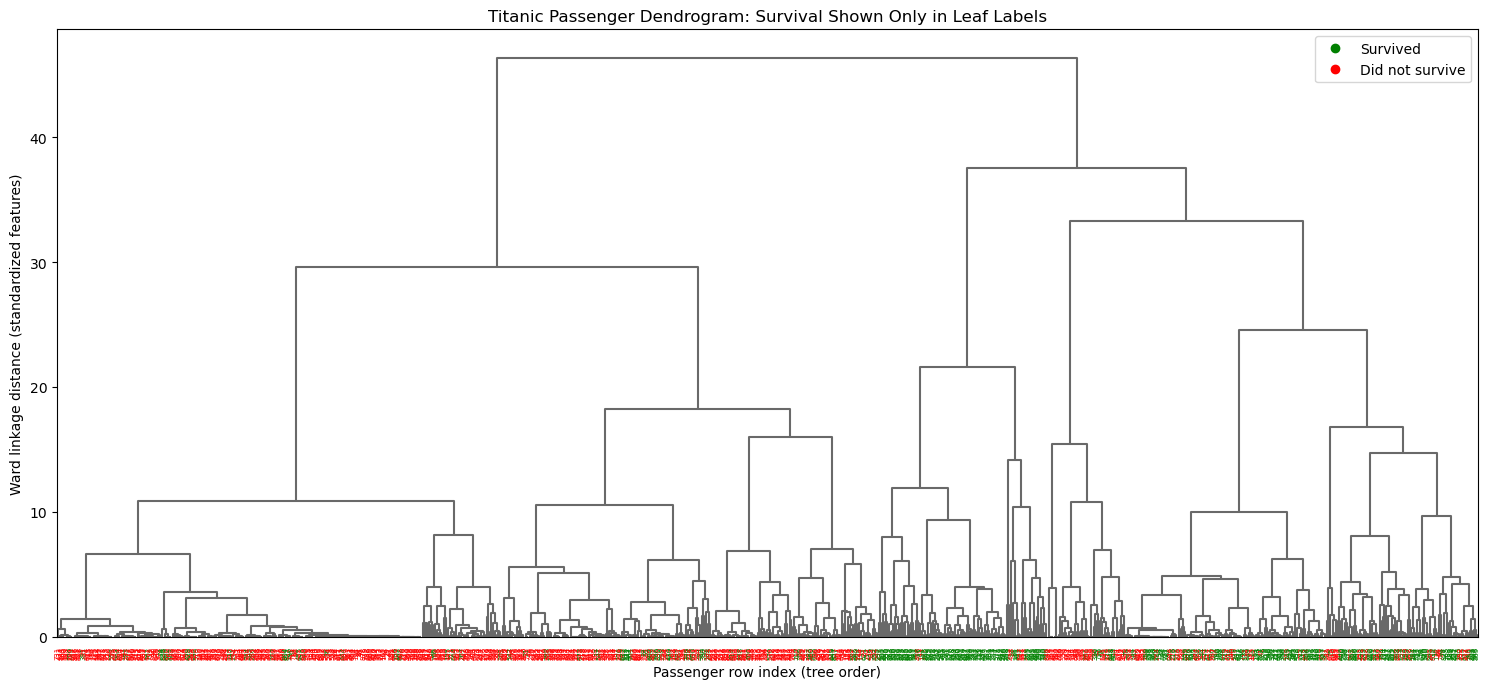

In [67]:
plt.figure(figsize=(15, 7))
dendrogram_result = sch.dendrogram(
    linkage_matrix,
    labels=titanic_cluster_df.index.astype(str).tolist(),
    leaf_rotation=90,
    leaf_font_size=5,
    color_threshold=0,
    above_threshold_color="dimgray"
)
for label in plt.gca().get_xmajorticklabels():
    passenger_index = int(label.get_text())
    label.set_color("green" if titanic_cluster_df.loc[passenger_index, "Survived"] == 1 else "red")
plt.title("Titanic Passenger Dendrogram: Survival Shown Only in Leaf Labels")
plt.xlabel("Passenger row index (tree order)")
plt.ylabel("Ward linkage distance (standardized features)")
plt.legend(handles=[
    Line2D([], [], color="green", marker="o", linestyle="None", label="Survived"),
    Line2D([], [], color="red", marker="o", linestyle="None", label="Did not survive")
])
plt.tight_layout()
plt.show()


**Where do you see large vertical gaps between merges? What might change when we cut the tree into two, three, or five clusters? Can you tell what characterizes each group from the tree alone?**


## Compare two, three, and five clusters

Use the same hierarchy for each comparison. Display cluster sizes, feature means in their original units, and survival percentages. `Sex` is coded 0/1 here, so its mean is the proportion recorded as female. The mean of `Pclass` summarizes the numerical class codes; it is not a literal passenger class. Cluster numbers are arbitrary labels, not ranks, and their identities need not match between cuts.


### 2 clusters


In [ ]:
titanic_cluster_df["cluster_2"] = sch.fcluster(linkage_matrix, t=2, criterion="maxclust")
titanic_cluster_df.groupby("cluster_2").size().to_frame("passenger_count")


In [ ]:
titanic_cluster_df.groupby("cluster_2")[cluster_features].mean().round(2)


In [ ]:
titanic_cluster_df.groupby("cluster_2")["Survived"].mean().mul(100).round(1).to_frame("survival_percent")


### 3 clusters


In [ ]:
titanic_cluster_df["cluster_3"] = sch.fcluster(linkage_matrix, t=3, criterion="maxclust")
titanic_cluster_df.groupby("cluster_3").size().to_frame("passenger_count")


In [ ]:
titanic_cluster_df.groupby("cluster_3")[cluster_features].mean().round(2)


In [ ]:
titanic_cluster_df.groupby("cluster_3")["Survived"].mean().mul(100).round(1).to_frame("survival_percent")


### 5 clusters


In [ ]:
titanic_cluster_df["cluster_5"] = sch.fcluster(linkage_matrix, t=5, criterion="maxclust")
titanic_cluster_df.groupby("cluster_5").size().to_frame("passenger_count")


In [ ]:
titanic_cluster_df.groupby("cluster_5")[cluster_features].mean().round(2)


In [ ]:
titanic_cluster_df.groupby("cluster_5")["Survived"].mean().mul(100).round(1).to_frame("survival_percent")


## Discussion: what do these groups tell us?

- Which features distinguish the clusters at each cut? Cite a mean and group size.
- What extra detail appears as we move from two to three to five groups?
- Do clusters have different survival percentages even though survival was not used to form them?
- Why would different feature choices, missing-age handling, or scaling potentially change the groups?


## Limitations of the demonstration

Using class codes and a binary sex code in standardized Euclidean geometry makes assumptions about distances and feature weights; this is an illustration, not a claim that this is the best clustering method for mixed data. Median-filled ages, outliers in fare, and historical data uncertainty can affect the tree. The clusters do not establish causes of survival or uniquely true passenger types.
